# Customer Churn & Retention Analysis

## 1. Data Loading and Initial Inspection

In [1]:
import pandas as pd
from pathlib import Path

# Identify the project folder
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Dataset path
csv_path = project_root / "data" / "raw" / "Telco-Customer-Churn.csv"

print("File exists:", csv_path.exists())

File exists: True


In [2]:
churm_df = pd.read_csv(csv_path)
print(churm_df.shape)
display(churm_df.head(5))
display(churm_df.columns.tolist())
rows, columns = churm_df.shape
print(f"Number of rows: {rows}")
print(f"Number of columns: {columns}")

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

Number of rows: 7043
Number of columns: 21


In [3]:
print(churm_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
churm_df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [5]:
churm_df.isna().mean() * 100

customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64

In [6]:
churm_df.duplicated().sum()

np.int64(0)

In [7]:
print("TotalCHarges data type:", churm_df["TotalCharges"].dtype)

blank_charges = churm_df["TotalCharges"].str.strip().eq("")

print("Number of blank TotalCharges:", blank_charges.sum())

display(
    churm_df.loc[
        blank_charges,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

TotalCHarges data type: object
Number of blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [8]:
# Remove the blanks in TotalCharges with zero
churm_df["TotalCharges"] = (
    churm_df["TotalCharges"]
    .str.strip()
    .replace("", "0")
)

# Convert TotalCharges into numeric format
churm_df["TotalCharges"] = pd.to_numeric(
    churm_df["TotalCharges"]
)

# Verify
print("Data type:", churm_df["TotalCharges"].dtype)

print("Missing values:",
      churm_df["TotalCharges"].isna().sum()
)

print(
    "TotalCharges equal to zero:",
    (churm_df["TotalCharges"] == 0).sum()
)

Data type: float64
Missing values: 0
TotalCharges equal to zero: 11


In [9]:
categorical_columns = churm_df.select_dtypes(include="object").columns
print(categorical_columns)
print(categorical_columns.nunique())

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='object')
17


In [10]:
churm_df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [11]:
churm_df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [12]:
churm_df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [13]:
churm_df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [14]:
# Identify categorical columns
categorical_columns = (
    churm_df
    .select_dtypes(include = "object")
    .columns
    .drop("customerID")
)

# Count unique values in each categorical column
category_counts = churm_df[categorical_columns].nunique()
print("Unique values in each categorical column:")
display(category_counts.sort_values(ascending = False))

Unique values in each categorical column:


PaymentMethod       4
MultipleLines       3
InternetService     3
OnlineSecurity      3
OnlineBackup        3
DeviceProtection    3
TechSupport         3
StreamingTV         3
StreamingMovies     3
Contract            3
gender              2
Partner             2
Dependents          2
PhoneService        2
PaperlessBilling    2
Churn               2
dtype: int64

In [15]:
# SeniorCitizen as a categorical values
print("SeniorCitizen distribution:", churm_df["SeniorCitizen"].value_counts())

SeniorCitizen distribution: SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


In [16]:
# Customer churn percentage
churn_percentage = churm_df["Churn"].value_counts(normalize=True) * 100

# Customer churn counts
churn_counts = churm_df["Churn"].value_counts()

# Combine
churn_summary = pd.DataFrame({
    "Customers": churn_counts,
    "Percentage": churn_percentage
})

print(churn_summary)

       Customers  Percentage
Churn                       
No          5174   73.463013
Yes         1869   26.536987


If tThe overall customer churn rate of 26.54% represents a significant customer-retention concern. Approximately one in four customers has left the company, indicating potential weaknesses in customer retention. Further analysis is required to identify the factors associated with churn and determine which customer segments require targeted retention strategies.

In [17]:
contract_counts = (
    churm_df.groupby(["Contract", "Churn"])
    .size()
    .unstack()
)
print(contract_counts)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [18]:
#Total customers per contract
Total_Customers = contract_counts.sum(axis = 1)

# Churned customers per contract
Churned_Customers = contract_counts["Yes"]

#Contract-wise churn %
Churn_Rate = (Churned_Customers.div(Total_Customers) * 100).round(2)

# Summary DataFrame
contract_summary = pd.DataFrame({
    "Total_Customers": Total_Customers,
    "Churned_Customers": Churned_Customers,
    "Churn_Rate_%": Churn_Rate
})

display(contract_summary)

,Total_Customers,Churned_Customers,Churn_Rate_%
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


Month-to-month customers exhibit the highest churn rate at 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts. This suggests that longer-term contracts are associated with stronger customer retention. The company should investigate targeted retention strategies for month-to-month customers.

In [19]:
contract_metrics = (
    churm_df
    .groupby("Contract")
    .agg(
        Total_Customers = ("customerID", "count"),
        Churned_Customers = ("Churn", lambda x: (x == "Yes").sum()),
        Avg_Tenure = ("tenure", "mean"),
        Avg_Monthly_Charges = ("MonthlyCharges", "mean"),
        Avg_Total_Charges = ("TotalCharges", "mean")
    )
)

# Churn %
contract_metrics["Churn_Rate_%"] = (
    contract_metrics["Churned_Customers"]
    .div(contract_metrics["Total_Customers"])
    * 100
).round(2)

# Sort Churn %
contract_metrics = contract_metrics.sort_values(
    "Churn_Rate_%",
    ascending = False
)

display(contract_metrics.round(2))

,Total_Customers,Churned_Customers,Avg_Tenure,Avg_Monthly_Charges,Avg_Total_Charges,Churn_Rate_%
Contract,,,,,,
Month-to-month,3875,1655,18.04,66.40,1369.25,42.71
One year,1473,166,42.04,65.05,3032.62,11.27
Two year,1695,48,56.74,60.77,3706.93,2.83


In [21]:
# Month-to-month customers pay 66.40 on average.
# One-year customers pay 65.05 —> only 1.35 less.
# Yet their churn rates are dramatically different: 42.71% vs 11.27%.

In [20]:
monthly_charge_analysis = (
    churm_df.groupby("Churn").agg(
    Total_Customers = ("customerID", "count"),
    Avg_Monthly_Charges = ("MonthlyCharges", "mean"),
    Median_Monthly_Charges = ("MonthlyCharges", "median")
    ).round(2)
)
display(monthly_charge_analysis)

,Total_Customers,Avg_Monthly_Charges,Median_Monthly_Charges
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


In [21]:
tenure_analysis = (
    churm_df.groupby("Churn").agg(
    Total_Customers = ("customerID", "count"),
    Avg_tenure = ("tenure", "mean"),
    Median_tenure = ("tenure", "median"),
    Min_tenure = ("tenure", "min"),
    Max_tenure = ("tenure", "max"),
    ).round(2)
)
display(tenure_analysis)

,Total_Customers,Avg_tenure,Median_tenure,Min_tenure,Max_tenure
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


Customers who churned had substantially shorter tenure than customers who stayed, with an average tenure of approximately 18 months compared with 38 months. This indicates that customer retention may be particularly challenging during the early stages of the customer relationship. The business should investigate the first 12–24 months of the customer lifecycle to identify opportunities for improving retention.

In [22]:
bins = [-1, 12, 24, 48, 72]
labels = [
    "0-12 months", 
    "13-24 months", 
    "25-48 months", 
    "49-72 months"
]

churm_df["Tenure_Group"] = pd.cut(churm_df["tenure"], bins = bins, labels = labels)

print(churm_df[["tenure", "Tenure_Group"]].head(10))

print(churm_df["Tenure_Group"].value_counts(sort = False))

   tenure  Tenure_Group
0       1   0-12 months
1      34  25-48 months
2       2   0-12 months
3      45  25-48 months
4       2   0-12 months
5       8   0-12 months
6      22  13-24 months
7      10   0-12 months
8      28  25-48 months
9      62  49-72 months
Tenure_Group
0-12 months     2186
13-24 months    1024
25-48 months    1594
49-72 months    2239
Name: count, dtype: int64


In [23]:
tenure_counts = (
    churm_df
    .groupby(
        ["Tenure_Group", "Churn"], 
        observed = False
    )
    .size()
    .unstack()
)

total_customers = tenure_counts.sum(axis = 1)

churned_customers = tenure_counts["Yes"]

churn_rate = (churned_customers.div(total_customers) * 100)

In [24]:
tenure_summary = pd.DataFrame({
    "Total_Customers": total_customers,
    "Churned_Customers": churned_customers,
    "Churn_Rate_%": churn_rate
}).round(2)
tenure_summary = tenure_summary.sort_values(
    "Churn_Rate_%",
    ascending = False
)
display(tenure_summary)

,Total_Customers,Churned_Customers,Churn_Rate_%
Tenure_Group,,,
0-12 months,2186,1037,47.44
13-24 months,1024,294,28.71
25-48 months,1594,325,20.39
49-72 months,2239,213,9.51


Customer churn is concentrated among customers with shorter tenure. The 0–12 month segment has the highest churn rate at 47.44%, while customers with 49–72 months of tenure have the lowest rate at 9.51%. This suggests that early customer engagement and onboarding should be investigated as potential retention priorities.

Customer churn is concentrated among customers with shorter tenure. The 0–12 month segment has the highest churn rate at 47.44%, while customers with 49–72 months of tenure have the lowest rate at 9.51%. This suggests that early customer engagement and onboarding should be investigated as potential retention priorities.

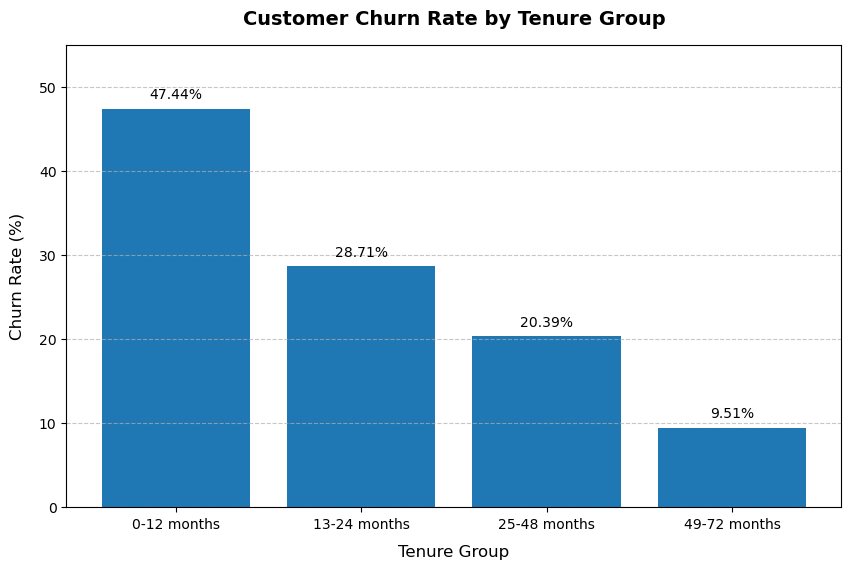

In [25]:
import matplotlib.pyplot as plt
# Visualization canvas size
plt.figure(figsize = (10, 6))
# The bar chart using tenure summary
bars = plt.bar(
    tenure_summary.index,
    tenure_summary["Churn_Rate_%"],
)
plt.bar_label(
    bars,
    fmt = "%.2f%%",
    padding = 5
)
plt.ylim(0, 55)
plt.title(
    "Customer Churn Rate by Tenure Group", fontsize = 14, fontweight = "bold", pad = 15
)
plt.xlabel("Tenure Group", fontsize = 12, labelpad = 10)
plt.ylabel("Churn Rate (%)", fontsize = 12, labelpad = 10)
plt.grid(axis = "y", linestyle = "--", alpha = 0.7)
plt.tight_layout
figures_dir = project_root / "reports" / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "01_churn_by_tenure.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [26]:
internet_counts = (
    churm_df
    .groupby(["InternetService", "Churn"])
    .size()
    .unstack()
)
total_customers = internet_counts.sum(axis = 1)
churned_customers = internet_counts["Yes"]
churn_rate = churned_customers.div(total_customers) * 100

In [27]:
internet_summary = pd.DataFrame({
    "Total_Customers": total_customers,
    "Churned_Customers": churned_customers,
    "Churn_Rate_%": churn_rate
}).round(2)
internet_summary = internet_summary.sort_values(
    "Churn_Rate_%",
    ascending = False
)
display(internet_summary)

,Total_Customers,Churned_Customers,Churn_Rate_%
InternetService,,,
Fiber optic,3096,1297,41.89
DSL,2421,459,18.96
No,1526,113,7.40


In [28]:
security_counts = (
    churm_df
    .groupby(["OnlineSecurity", "Churn"])
    .size()
    .unstack()
)
total_customers = security_counts.sum(axis = 1)
churned_customers = security_counts["Yes"]
churn_rate = churned_customers.div(total_customers) * 100
security_summary = pd.DataFrame({
    "Total_Customers": total_customers,
    "Churned_Customers": churned_customers,
    "Churn_Rate_%": churn_rate
}).round(2)
security_summary = security_summary.sort_values(
    "Churn_Rate_%",
    ascending = False
)
display(security_summary)

,Total_Customers,Churned_Customers,Churn_Rate_%
OnlineSecurity,,,
No,3498,1461,41.77
Yes,2019,295,14.61
No internet service,1526,113,7.40


In [29]:
support_counts = (
    churm_df
    .groupby(["TechSupport", "Churn"])
    .size()
    .unstack()
)
total_customers = support_counts.sum(axis = 1)
churned_customers = support_counts["Yes"]
churn_rate = churned_customers.div(total_customers) * 100
support_summary = pd.DataFrame({
    "Total_Customers": total_customers,
    "Churned_Customers": churned_customers,
    "Churn_Rate_%": churn_rate
}).round(2)
support_summary = support_summary.sort_values(
    "Churn_Rate_%",
    ascending = False
)
display(support_summary)

,Total_Customers,Churned_Customers,Churn_Rate_%
TechSupport,,,
No,3473,1446,41.64
Yes,2044,310,15.17
No internet service,1526,113,7.40


In [30]:
internet_customers = churm_df[
    churm_df["InternetService"] != "No"
].copy()

In [31]:
service_combo_counts = (
    internet_customers
    .groupby(
        ["OnlineSecurity", "TechSupport", "Churn"]
    )
    .size()
    .unstack(fill_value = 0)
)
total_customers = service_combo_counts.sum(axis = 1)
churned_customers = service_combo_counts["Yes"]
churn_rate = churned_customers.div(total_customers) * 100
service_combo_summary = pd.DataFrame({
    "Total_Customers": total_customers,
    "Churned_Customers": churned_customers,
    "Churn_Rate_%": churn_rate
}).round(2)
service_combo_summary = service_combo_summary.sort_values(
    "Churn_Rate_%",
    ascending = False
)
display(service_combo_summary)

Total_Customers  Churned_Customers  Churn_Rate_%
OnlineSecurity TechSupport                                                  
No             No                      2553               1250         48.96
               Yes                      945                211         22.33
Yes            No                       920                196         21.30
               Yes                     1099                 99          9.01

Customers without Online Security and Tech Support have the highest churn rate at 48.96%, whereas customers subscribed to both services have the lowest rate at 9.01%. This suggests that additional service engagement is associated with stronger customer retention. The company should investigate targeted service bundles and customer engagement initiatives, particularly for customers without either service.

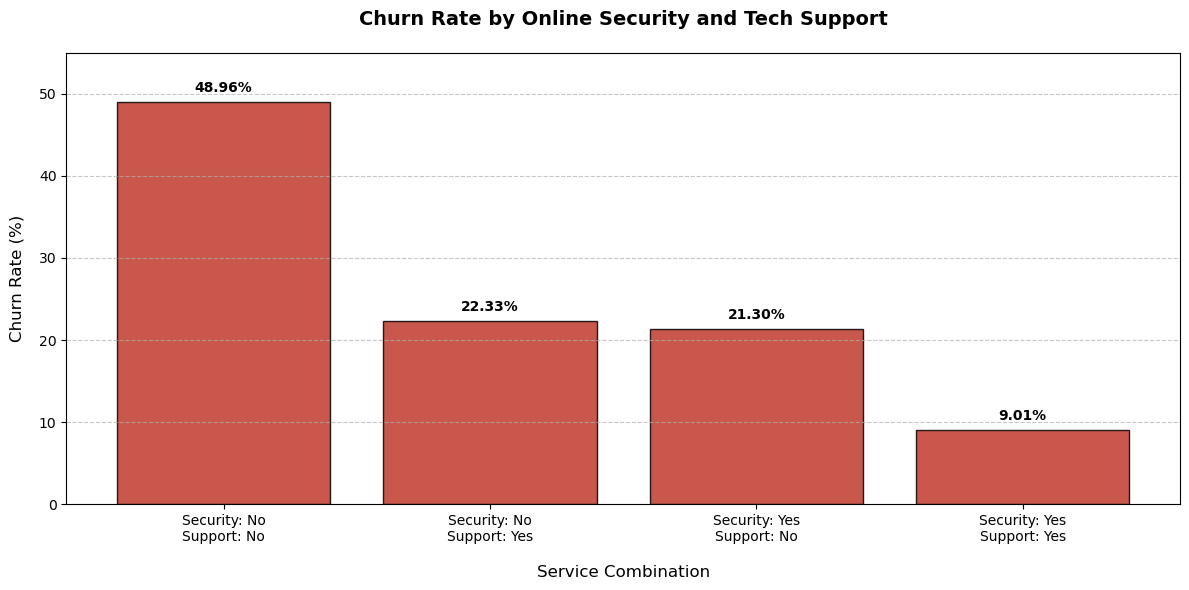

In [32]:
plt.figure(figsize=(12, 6))

combo_labels = [
    f"Security: {security}\nSupport: {support}"
    for security, support in service_combo_summary.index
]

bars = plt.bar(
    combo_labels,
    service_combo_summary["Churn_Rate_%"],
    color="#c0392b",
    edgecolor="black",
    alpha=0.85,
)

plt.title(
    "Churn Rate by Online Security and Tech Support",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Service Combination", fontsize=12, labelpad=15)
plt.ylabel("Churn Rate (%)", fontsize=12, labelpad=10)

plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.bar_label(bars, fmt="%.2f%%", padding=5, fontsize=10, fontweight="bold")

plt.ylim(0, 55)

plt.tight_layout()

figures_dir = project_root / "reports" / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "02_churn_by_service_combination.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [33]:
revenue_analysis = churm_df.groupby("Churn").agg(
    Total_Customers = ("customerID", "count"),
    Avg_monthly_charges = ("MonthlyCharges", "mean"),
    Total_monthly_charges = ("MonthlyCharges", "sum"),
    Avg_total_charges = ("TotalCharges", "mean"),
    ).round(2)
display(revenue_analysis)

,Total_Customers,Avg_monthly_charges,Total_monthly_charges,Avg_total_charges
Churn,,,,
No,5174,61.27,316985.75,2549.91
Yes,1869,74.44,139130.85,1531.80


In [34]:
churned_monthly_charges = revenue_analysis.loc["Yes", "Total_monthly_charges"]
Total_monthly_charges = revenue_analysis["Total_monthly_charges"].sum()

In [35]:
revenue_share = ((churned_monthly_charges/Total_monthly_charges) * 100).round(2)
print(revenue_share)

30.5


Customers who churned accounted for 139,130.85 in monthly charges, representing 30.50% of the total monthly charges recorded across the customer base. This highlights the financial significance of customer retention. The company should prioritise understanding the characteristics of high-value customers who leave and developing suitable retention initiatives.

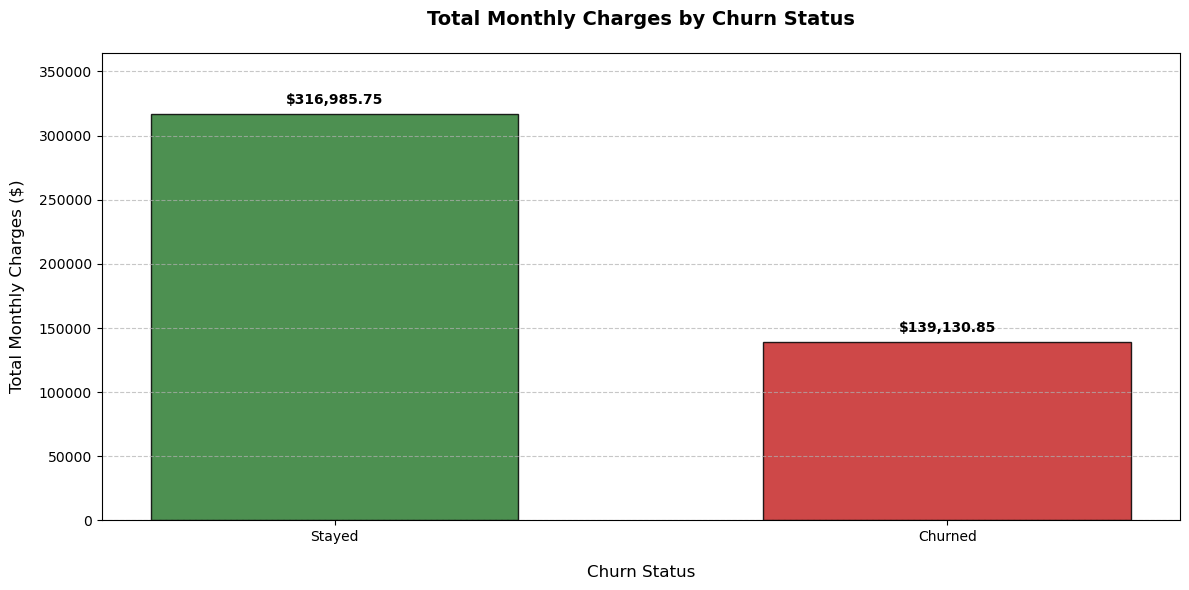

In [36]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

bars = plt.bar(
    revenue_analysis.index,
    revenue_analysis["Total_monthly_charges"],
    color=["#2e7d32", "#c62828"],
    edgecolor="black",
    alpha=0.85,
    width=0.6
)

plt.title(
    "Total Monthly Charges by Churn Status",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Churn Status", fontsize=12, labelpad=15)
plt.ylabel("Total Monthly Charges ($)", fontsize=12, labelpad=10)

plt.xticks(
    ticks = [0, 1],
    labels = ["Stayed", "Churned"]
)

plt.grid(axis="y", linestyle="--", alpha=0.7)

labels = [
    f"${value:,.2f}"
    for value in bars.datavalues
]

plt.bar_label(
    bars,
    labels = labels,
    padding = 5,
    fontsize = 10,
    fontweight = "bold"

)
plt.ylim(
    0,
    revenue_analysis["Total_monthly_charges"].max() * 1.15
)

plt.tight_layout()

figures_dir = project_root / "reports" / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "03_monthly_charges_by_churn.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [37]:
churned_df = churm_df[
    churm_df["Churn"] == "Yes"
].copy()
churned_contract_summary = (
    churned_df
    .groupby("Contract")
    .agg(
        Churned_Customers=("customerID", "count"),
        Avg_Monthly_Charges=("MonthlyCharges", "mean"),
        Total_Monthly_Charges=("MonthlyCharges", "sum")
    )
    .round(2)
)

churned_contract_summary = (
    churned_contract_summary.sort_values(
        "Total_Monthly_Charges", 
        ascending = False
    )
)

display(churned_contract_summary)

,Churned_Customers,Avg_Monthly_Charges,Total_Monthly_Charges
Contract,,,
Month-to-month,1655,73.02,120847.10
One year,166,85.05,14118.45
Two year,48,86.78,4165.30


Month-to-month customers represent the largest financial exposure, accounting for 120,847.10 in monthly charges associated with churned customers. Despite having lower average monthly charges than longer-contract customers, their significantly higher churn volume makes them the most important segment for retention analysis. The company should investigate targeted retention initiatives for this group.

In [38]:
total_monthly_charges = churned_contract_summary["Total_Monthly_Charges"].sum()
churned_contract_summary["Revenue_Contribution_%"] = (
    churned_contract_summary["Total_Monthly_Charges"]
    .div(total_monthly_charges)
    .mul(100)
    .round(2)
)

display(churned_contract_summary)

,Churned_Customers,Avg_Monthly_Charges,Total_Monthly_Charges,Revenue_Contribution_%
Contract,,,,
Month-to-month,1655,73.02,120847.10,86.86
One year,166,85.05,14118.45,10.15
Two year,48,86.78,4165.30,2.99


Month-to-month customers contribute 86.86% of the total monthly charges associated with churned customers, making this the most financially significant contract segment. Despite having lower average monthly charges than longer-term contracts, the much higher number of churned customers drives its financial exposure. The company should prioritise retention initiatives targeting this segment.

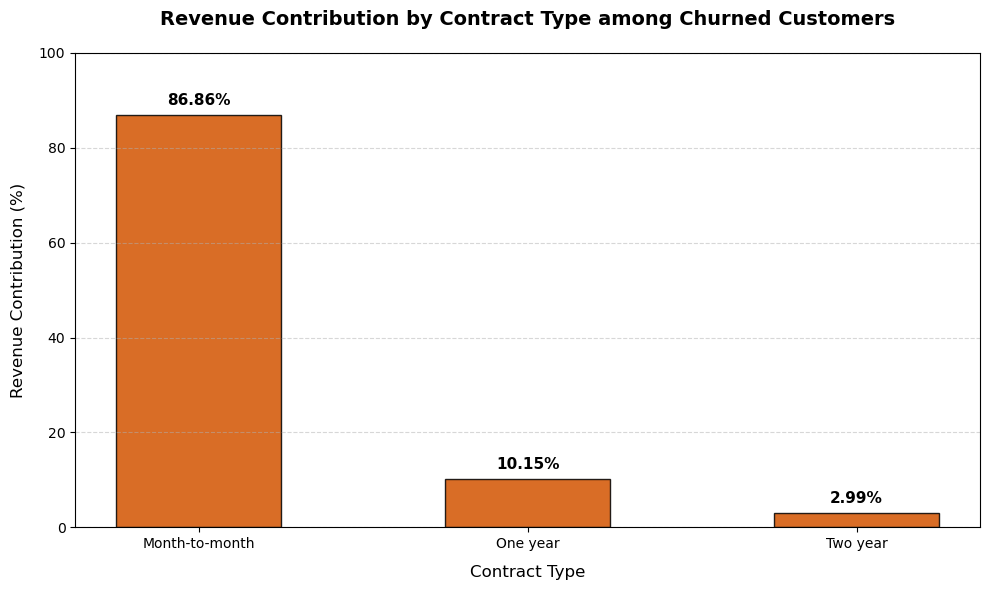

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    churned_contract_summary.index,
    churned_contract_summary["Revenue_Contribution_%"],
    color="#d35400",  # Professional burnt orange to denote revenue exposure
    edgecolor="black",
    alpha=0.85,
    width=0.5,
)

plt.title(
    "Revenue Contribution by Contract Type among Churned Customers",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Contract Type", fontsize=12, labelpad=10)
plt.ylabel("Revenue Contribution (%)", fontsize=12, labelpad=10)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.bar_label(bars, fmt="%.2f%%", padding=5, fontsize=11, fontweight="bold")

plt.ylim(0, 100)

plt.tight_layout()

figures_dir = project_root / "reports" / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "04_revenue_contribution_by_contract.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [41]:
tenure_revenue = (
    churned_df
    .groupby("Tenure_Group", observed = False)
    .agg(
        Churned_Customers = ("customerID", "count"),
        Avg_Monthly_Charges = ("MonthlyCharges", "mean"),
        Total_Monthly_Charges = ("MonthlyCharges", "sum"),
        Avg_Total_Charges = ("TotalCharges", "mean")
    ).round(2)
)
display(tenure_revenue)

,Churned_Customers,Avg_Monthly_Charges,Total_Monthly_Charges,Avg_Total_Charges
Tenure_Group,,,,
0-12 months,1037,66.49,68954.25,288.53
13-24 months,294,78.51,23081.65,1394.78
25-48 months,325,84.50,27462.50,3003.14
49-72 months,213,92.17,19632.45,5528.80


In [42]:
total_tenure_charges = (
    tenure_revenue["Total_Monthly_Charges"].sum()
)
print(total_tenure_charges)

139130.85


In [43]:
tenure_revenue["Revenue_Contribution_%"] = (
    tenure_revenue["Total_Monthly_Charges"]
    .div(total_tenure_charges)
    .mul(100)
    .round(2)
)

tenure_revenue = tenure_revenue.sort_values(
    "Revenue_Contribution_%",
    ascending = False
)

display(tenure_revenue)

,Churned_Customers,Avg_Monthly_Charges,Total_Monthly_Charges,Avg_Total_Charges,Revenue_Contribution_%
Tenure_Group,,,,,
0-12 months,1037,66.49,68954.25,288.53,49.56
25-48 months,325,84.50,27462.50,3003.14,19.74
13-24 months,294,78.51,23081.65,1394.78,16.59
49-72 months,213,92.17,19632.45,5528.80,14.11


### Business Observation — Revenue Exposure by Customer Tenure

Customers in their first 12 months account for 49.56% of monthly charges associated with churned customers, making them the largest financial exposure segment. Although long-term churned customers have higher average monthly charges, early-stage customers contribute more to the overall exposure due to their higher churn volume. The company should prioritise early customer engagement, onboarding and targeted retention initiatives.

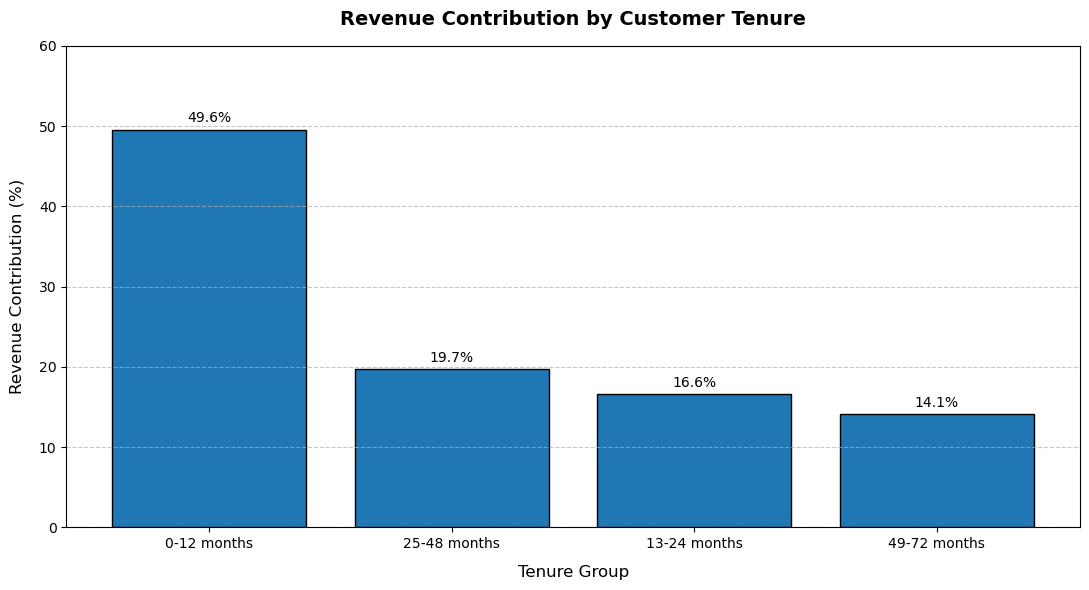

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

bars = plt.bar(
    tenure_revenue.index, 
    tenure_revenue["Revenue_Contribution_%"], 
    color="#1f77b4", 
    edgecolor="black"
)

plt.bar_label(bars, fmt='%.1f%%', padding=3)

plt.title("Revenue Contribution by Customer Tenure", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Tenure Group", fontsize=12, labelpad=10)
plt.ylabel("Revenue Contribution (%)", fontsize=12, labelpad=10)

plt.ylim(0, 60)

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()

figures_dir = project_root / "reports" / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "05_revenue_contribution_by_tenure.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [45]:
payment_counts = (
    churm_df
    .groupby(["PaymentMethod", "Churn"])
    .size()
    .unstack()
)

display(payment_counts)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [46]:
print("Tenure_Group" in churm_df.columns)

True


In [47]:
contract_tenure_counts = (
    churm_df
    .groupby(
        ["Contract", "Tenure_Group", "Churn"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
)

display(contract_tenure_counts)

Churn                          No   Yes
Contract       Tenure_Group            
Month-to-month 0-12 months    970  1024
               13-24 months   459   278
               25-48 months   538   264
               49-72 months   253    89
One year       0-12 months    111    13
               13-24 months   181    16
               25-48 months   463    55
               49-72 months   552    82
Two year       0-12 months     68     0
               13-24 months    90     0
               25-48 months   268     6
               49-72 months  1221    42

In [48]:
total_customers = contract_tenure_counts.sum(axis = 1)
churned_customers = contract_tenure_counts["Yes"]
retained_customers = contract_tenure_counts["No"]
churn_rate = (churned_customers.div(total_customers) * 100).round(2)

contract_tenure_summary = pd.DataFrame({
    "Total_Customers": total_customers,
    "Churned_Customers": churned_customers,
    "Retained_Customers": retained_customers,
    "Churn_Rate_%": churn_rate
}).round(2)

contract_tenure_summary = contract_tenure_summary.sort_values("Churn_Rate_%", ascending = False)

display(contract_tenure_summary)

Total_Customers  Churned_Customers  \
Contract       Tenure_Group                                       
Month-to-month 0-12 months              1994               1024   
               13-24 months              737                278   
               25-48 months              802                264   
               49-72 months              342                 89   
One year       49-72 months              634                 82   
               25-48 months              518                 55   
               0-12 months               124                 13   
               13-24 months              197                 16   
Two year       49-72 months             1263                 42   
               25-48 months              274                  6   
               0-12 months                68                  0   
               13-24 months               90                  0   

                             Retained_Customers  Churn_Rate_%  
Contract       Tenure_Group                                    
Month-to-month 0-12 months                  970         51.35  
               13-24 months                 459         37.72  
               25-48 months                 538         32.92  
               49-72 months                 253         26.02  
One year       49-72 months                 552         12.93  
               25-48 months                 463         10.62  
               0-12 months                  111         10.48  
               13-24 months                 181          8.12  
Two year       49-72 months                1221          3.33  
               25-48 months                 268          2.19  
               0-12 months                   68          0.00  
               13-24 months                  90          0.00

### Business Observation — Contract Type and Customer Tenure

The analysis identifies month-to-month customers with 0–12 months of tenure as the highest-risk segment, with a churn rate of 51.35%. Month-to-month customers demonstrate elevated churn across all tenure groups, whereas two-year contract customers have substantially lower churn rates. The company should prioritise early-stage onboarding, proactive customer engagement and retention initiatives for month-to-month subscribers.

The findings suggest that contract duration and customer tenure are important characteristics associated with customer retention.

## Export Cleaned Dataset for SQL Analysis

In [50]:
processed_dir = project_root / "data" / "processed"

processed_dir.mkdir(parents=True, exist_ok=True)

sql_df = churm_df.drop(
    columns=["Tenure_Group"],
    errors="ignore"
)

cleaned_csv_path = (
    processed_dir / "telco_customer_churn_cleaned.csv"
)

sql_df.to_csv(cleaned_csv_path, index=False)

print("File saved:", cleaned_csv_path.exists())
print("Dataset shape:", sql_df.shape)
print("TotalCharges dtype:", sql_df["TotalCharges"].dtype)
print("Missing TotalCharges:", sql_df["TotalCharges"].isna().sum())

File saved: True
Dataset shape: (7043, 21)
TotalCharges dtype: float64
Missing TotalCharges: 0
